# 07 — XGBoost per generator

**Group 119 — Henrik Remmen (541747)**  
**Kaggle team:** `[119] SINTEF Databreach`

This experiment trains one histogram-based XGBoost classifier per generator using the same engineered features and chronological validation as notebooks 04 and 05.

> Saved unexecuted. Run it yourself after CatBoost so the experiments remain easy to track.


## 1. Setup and data

In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.sintef_pipeline import (
    HORIZON,
    RANDOM_SEED,
    build_project_data,
    make_submission,
    micro_auc,
    per_unit_auc,
    rows_for_cases,
)

try:
    from xgboost import XGBClassifier
except ImportError as error:
    raise ImportError(
        "Install project dependencies with: pip install -r requirements.txt"
    ) from error

sns.set_theme(style="whitegrid", context="notebook")
FEATURE_SET = "full_engineered"
N_JOBS = 4

print("Project root:", ROOT.resolve())


Project root: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project


In [2]:
# DATA/FEATURE CELL — does not train a model
data = build_project_data(ROOT)
FEATURES = data.feature_sets[FEATURE_SET]

print("Feature set:", FEATURE_SET)
print("Number of features:", len(FEATURES))
print("Feature matrix:", data.X_all.shape)
print("Target cube:", data.target_cube.shape)
display(pd.DataFrame([
    {
        "validation_year": fold["year"],
        "train_cases": len(fold["train_cases"]),
        "validation_cases": len(fold["validation_cases"]),
    }
    for fold in data.folds
]))


Feature set: full_engineered
Number of features: 175
Feature matrix: (612696, 175)
Target cube: (2922, 14, 168)


,validation_year,train_cases,validation_cases
0,2020,1820,366
1,2021,2186,365
2,2022,2551,365


## 2. XGBoost definition and OOF validation

In [3]:
XGBOOST_PARAMS = {
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "max_depth": 7,
    "min_child_weight": 50,
    "subsample": 0.85,
    "colsample_bytree": 0.85,
    "reg_alpha": 0.1,
    "reg_lambda": 5.0,
    "gamma": 0.0,
    "tree_method": "hist",
    "max_bin": 256,
    "random_state": RANDOM_SEED,
    "n_jobs": N_JOBS,
    "early_stopping_rounds": 120,
}

def make_xgboost(n_estimators=None, early_stopping=True):
    params = dict(XGBOOST_PARAMS)
    if n_estimators is not None:
        params["n_estimators"] = int(n_estimators)
    if not early_stopping:
        params.pop("early_stopping_rounds", None)
    return XGBClassifier(**params)

def evaluate_xgboost_per_generator():
    oof = np.full(data.target_cube.shape, np.nan, dtype=np.float32)
    best_iterations = {unit: [] for unit in data.units}
    fold_rows = []
    unit_rows = []

    for fold in data.folds:
        started = time.perf_counter()
        train_case_ids = fold["train_cases"]
        val_case_ids = fold["validation_cases"]
        train_rows = rows_for_cases(train_case_ids)
        val_rows = rows_for_cases(val_case_ids)
        X_train = data.X_all.loc[train_rows, FEATURES]
        X_val = data.X_all.loc[val_rows, FEATURES]
        fold_prediction = np.empty(
            (len(val_case_ids), len(data.units), HORIZON),
            dtype=np.float32,
        )

        for unit_index, unit in enumerate(data.units):
            y_train = data.target_cube[train_case_ids, unit_index, :].reshape(-1)
            y_val = data.target_cube[val_case_ids, unit_index, :].reshape(-1)
            model = make_xgboost()
            model.fit(
                X_train,
                y_train,
                eval_set=[(X_val, y_val)],
                verbose=False,
            )
            best_iteration = int(model.best_iteration) + 1
            best_iterations[unit].append(best_iteration)
            prediction = model.predict_proba(
                X_val,
                iteration_range=(0, best_iteration),
            )[:, 1]
            fold_prediction[:, unit_index, :] = prediction.reshape(
                len(val_case_ids), HORIZON
            )

        oof[val_case_ids] = fold_prediction
        score = micro_auc(data.target_cube[val_case_ids], fold_prediction)
        elapsed = time.perf_counter() - started
        fold_rows.append({
            "validation_year": fold["year"],
            "micro_auc": score,
            "seconds": elapsed,
        })
        for unit, score_unit in per_unit_auc(
            data.target_cube[val_case_ids],
            fold_prediction,
            data.units,
        ).items():
            unit_rows.append({
                "validation_year": fold["year"],
                "unit": unit,
                "auc": score_unit,
            })
        print(
            f"XGBoost per generator | {fold['year']} | "
            f"micro AUC={score:.6f} | {elapsed:.1f}s"
        )

    return {
        "oof": oof,
        "best_iterations": best_iterations,
        "fold_scores": pd.DataFrame(fold_rows),
        "unit_scores": pd.DataFrame(unit_rows),
    }


In [4]:
# TRAINING CELL A — chronological OOF evaluation
xgboost_result = evaluate_xgboost_per_generator()
xgboost_fold_scores = xgboost_result["fold_scores"]

summary = {
    "model": "XGBoost per generator",
    "feature_set": FEATURE_SET,
    "n_features": len(FEATURES),
    "mean_auc": xgboost_fold_scores["micro_auc"].mean(),
    "worst_fold_auc": xgboost_fold_scores["micro_auc"].min(),
}
display(pd.DataFrame([summary]).style.format({
    "mean_auc": "{:.6f}",
    "worst_fold_auc": "{:.6f}",
}))

artifact_dir = ROOT / "artifacts" / "predictions"
artifact_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    artifact_dir / "xgboost_per_generator_oof.npz",
    oof=xgboost_result["oof"],
)
xgboost_fold_scores.to_csv(
    artifact_dir / "xgboost_per_generator_fold_scores.csv",
    index=False,
)


XGBoost per generator | 2020 | micro AUC=0.951148 | 260.6s
XGBoost per generator | 2021 | micro AUC=0.979491 | 405.2s
XGBoost per generator | 2022 | micro AUC=0.976270 | 597.7s


,model,feature_set,n_features,mean_auc,worst_fold_auc
0,XGBoost per generator,full_engineered,175,0.968969,0.951148


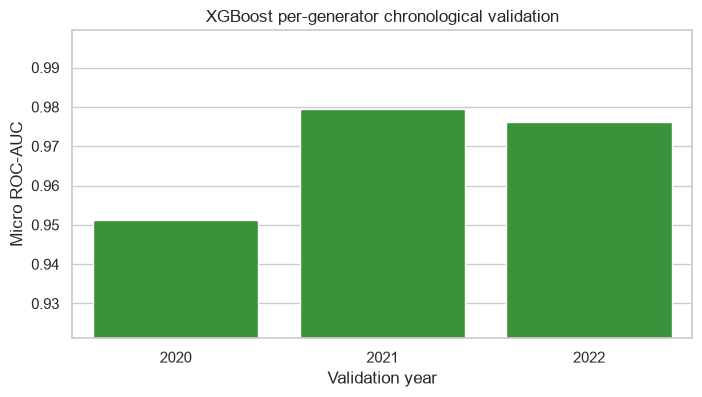

,mean,min
unit,,
Haukeli_G1,0.9004,0.8231
Lio_G1,0.9496,0.9125
Vinje_G3,0.9574,0.9261
Vinje_G2,0.9698,0.9575
Tokke_G4,0.9729,0.9592
Hogga_G1,0.9732,0.9705
Tokke_G2,0.9758,0.9624
Vinje_G1,0.9759,0.9648
Kjela_G1,0.9816,0.9780


In [5]:
# FAST ANALYSIS CELL — no training
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=xgboost_fold_scores,
    x="validation_year",
    y="micro_auc",
    color="tab:green",
    ax=ax,
)
ax.set(
    title="XGBoost per-generator chronological validation",
    xlabel="Validation year",
    ylabel="Micro ROC-AUC",
)
ax.set_ylim(
    max(0.5, xgboost_fold_scores["micro_auc"].min() - 0.03),
    min(1.0, xgboost_fold_scores["micro_auc"].max() + 0.02),
)
plt.show()

unit_summary = (
    xgboost_result["unit_scores"]
    .groupby("unit")["auc"]
    .agg(["mean", "min"])
    .sort_values("mean")
)
display(unit_summary.style.format("{:.4f}"))


## 3. Train on all labelled years and create submission

In [6]:
# TRAINING CELL B — final XGBoost models and submission
train_rows = rows_for_cases(np.arange(data.n_train_cases))
test_rows = rows_for_cases(
    np.arange(data.n_train_cases, data.n_all_cases)
)
X_train_full = data.X_all.loc[train_rows, FEATURES]
X_test = data.X_all.loc[test_rows, FEATURES]
test_prediction = np.empty(
    (data.n_test_cases, len(data.units), HORIZON),
    dtype=np.float32,
)

for unit_index, unit in enumerate(data.units):
    fold_iterations = xgboost_result["best_iterations"][unit]
    final_iterations = max(100, int(np.median(fold_iterations)))
    model = make_xgboost(
        n_estimators=final_iterations,
        early_stopping=False,
    )
    y_train = data.target_cube[:, unit_index, :].reshape(-1)
    model.fit(X_train_full, y_train, verbose=False)
    prediction = model.predict_proba(X_test)[:, 1]
    test_prediction[:, unit_index, :] = prediction.reshape(
        data.n_test_cases, HORIZON
    )
    print(f"{unit:18s}: {final_iterations} trees")

submission_path, submission = make_submission(
    data,
    test_prediction,
    "xgboost_per_generator.csv",
)
print("Saved:", submission_path)
display(submission.iloc[:3, :8])


Hogga_G1          : 410 trees
Tokke_G1          : 450 trees
Tokke_G2          : 854 trees
Tokke_G3          : 587 trees
Tokke_G4          : 693 trees
Lio_G1            : 249 trees
Byrte_G1          : 292 trees
Vinje_G1          : 658 trees
Vinje_G2          : 404 trees
Vinje_G3          : 607 trees
Haukeli_G1        : 223 trees
Songa_G1          : 510 trees
Kjela_G1          : 326 trees
Vesle Kjela_G1    : 372 trees
Saved: /Users/henrik/Documents/H26/Moderne Maksinlæring/sintef_project/submissions/xgboost_per_generator.csv


,Run No,result_committed_Hogga_G1_t0,result_committed_Hogga_G1_t1,result_committed_Hogga_G1_t2,result_committed_Hogga_G1_t3,result_committed_Hogga_G1_t4,result_committed_Hogga_G1_t5,result_committed_Hogga_G1_t6
0,2923,0.076481,0.061566,0.034630,0.027376,0.024515,0.018995,0.012900
1,2924,0.725795,0.732166,0.757163,0.820850,0.754422,0.819736,0.968743
2,2925,0.993399,0.993657,0.992774,0.992018,0.995500,0.997282,0.998862


### Kaggle description

`XGBoost per generator – full engineered features and purged OOF`

After all three model families finish, compare OOF residual correlations before creating a new blend.
